In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

from pathlib import Path

# Load dataset
file_path = Path("../data/Superstore.xls")

orders = pd.read_excel(file_path, sheet_name="Orders")
returns = pd.read_excel(file_path, sheet_name="Returns")
people = pd.read_excel(file_path, sheet_name="People")

print("Dataset loaded successfully!")
print("Orders:", orders.shape)
print("Returns:", returns.shape)
print("People:", people.shape)

C:\Users\USER\AppData\Local\Temp\ipykernel_41504\2233862415.py:12: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  orders = pd.read_excel(file_path, sheet_name="Orders")
C:\Users\USER\AppData\Local\Temp\ipykernel_41504\2233862415.py:13: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  returns = pd.read_excel(file_path, sheet_name="Returns")
C:\Users\USER\AppData\Local\Temp\ipykernel_41504\2233862415.py:14: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  people = pd.read_excel(file_path, sheet_name="People")


Dataset loaded successfully!
Orders: (10194, 21)
Returns: (800, 2)
People: (4, 2)


In [3]:
profit_model = smf.ols(
    "Profit ~ Sales + Quantity + Discount + C(Category) + C(Region) + C(Segment) + C(Q('Ship Mode'))",
    data=orders
).fit()

print(profit_model.summary())

                            OLS Regression Results                            
Dep. Variable:                 Profit   R-squared:                       0.283
Model:                            OLS   Adj. R-squared:                  0.282
Method:                 Least Squares   F-statistic:                     308.5
Date:                Thu, 26 Nov 2026   Prob (F-statistic):               0.00
Time:                        13:42:12   Log-Likelihood:                -68316.
No. Observations:               10194   AIC:                         1.367e+05
Df Residuals:                   10180   BIC:                         1.368e+05
Df Model:                          13                                         
Covariance Type:            nonrobust                                         
                                          coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------
In

In [4]:
# Display all regression coefficients
results = pd.DataFrame({
    "Coefficient": profit_model.params,
    "P-value": profit_model.pvalues,
    "Lower CI": profit_model.conf_int()[0],
    "Upper CI": profit_model.conf_int()[1]
})

print(results.round(4).to_string())

# Display model statistics
print("\nR-squared:", profit_model.rsquared)
print("Adjusted R-squared:", profit_model.rsquared_adj)
print("F-statistic:", profit_model.fvalue)
print("F-test p-value:", profit_model.f_pvalue)

                                     Coefficient  P-value  Lower CI  Upper CI
Intercept                                12.8837   0.1359   -4.0482   29.8156
C(Category)[T.Office Supplies]           48.7674   0.0000   39.0512   58.4837
C(Category)[T.Technology]                39.7500   0.0000   27.5467   51.9533
C(Region)[T.East]                       -11.1389   0.0441  -21.9839   -0.2940
C(Region)[T.South]                      -15.1595   0.0186  -27.7814   -2.5376
C(Region)[T.West]                       -15.2845   0.0055  -26.0722   -4.4969
C(Segment)[T.Corporate]                   3.0976   0.4882   -5.6607   11.8558
C(Segment)[T.Home Office]                 1.4790   0.7824   -9.0179   11.9758
C(Q('Ship Mode'))[T.Same Day]            -7.0430   0.4729  -26.2759   12.1898
C(Q('Ship Mode'))[T.Second Class]        -9.3286   0.1638  -22.4588    3.8016
C(Q('Ship Mode'))[T.Standard Class]      -5.3375   0.3416  -16.3384    5.6634
Sales                                     0.1848   0.0000    0.1

In [5]:
# Calculate regression with robust standard errors
robust_model = profit_model.get_robustcov_results(cov_type="HC3")

print(robust_model.summary())

                            OLS Regression Results                            
Dep. Variable:                 Profit   R-squared:                       0.283
Model:                            OLS   Adj. R-squared:                  0.282
Method:                 Least Squares   F-statistic:                     48.18
Date:                Thu, 26 Nov 2026   Prob (F-statistic):          1.43e-121
Time:                        14:04:18   Log-Likelihood:                -68316.
No. Observations:               10194   AIC:                         1.367e+05
Df Residuals:                   10180   BIC:                         1.368e+05
Df Model:                          13                                         
Covariance Type:                  HC3                                         
                                          coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------
In

# Regression Diagnostics

This section evaluates the reliability of the multiple linear regression model.

The analysis includes:
1. Multicollinearity analysis (VIF).
2. Heteroscedasticity test (Breusch-Pagan).
3. Residual analysis.

In [6]:
robust_results = pd.DataFrame({
    "Coefficient": robust_model.params,
    "Robust_P_Value": robust_model.pvalues
}, index=profit_model.params.index)

print(robust_results.round(5).to_string())

                                     Coefficient  Robust_P_Value
Intercept                               12.88367         0.39296
C(Category)[T.Office Supplies]          48.76741         0.00034
C(Category)[T.Technology]               39.74996         0.00000
C(Region)[T.East]                      -11.13891         0.09815
C(Region)[T.South]                     -15.15948         0.07730
C(Region)[T.West]                      -15.28453         0.00740
C(Segment)[T.Corporate]                  3.09759         0.49211
C(Segment)[T.Home Office]                1.47896         0.79653
C(Q('Ship Mode'))[T.Same Day]           -7.04305         0.55529
C(Q('Ship Mode'))[T.Second Class]       -9.32861         0.09257
C(Q('Ship Mode'))[T.Standard Class]     -5.33748         0.33539
Sales                                    0.18479         0.00142
Quantity                                -3.09909         0.28484
Discount                              -234.78843         0.00000


In [7]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from patsy import dmatrices

y, X = dmatrices(
    "Profit ~ Sales + Quantity + Discount + C(Category) + C(Region) + C(Segment) + C(Q('Ship Mode'))",
    data=orders,
    return_type="dataframe"
)

vif_results = pd.DataFrame({
    "Feature": X.columns,
    "VIF": [
        variance_inflation_factor(X.values, i)
        for i in range(X.shape[1])
    ]
})

print(vif_results.sort_values("VIF", ascending=False).round(3))

                                Feature    VIF
10  C(Q('Ship Mode'))[T.Standard Class]  1.985
9     C(Q('Ship Mode'))[T.Second Class]  1.843
5                     C(Region)[T.West]  1.728
3                     C(Region)[T.East]  1.665
1        C(Category)[T.Office Supplies]  1.547
2             C(Category)[T.Technology]  1.521
4                    C(Region)[T.South]  1.455
8         C(Q('Ship Mode'))[T.Same Day]  1.284
6               C(Segment)[T.Corporate]  1.107
7             C(Segment)[T.Home Office]  1.106
11                                Sales  1.099
13                             Discount  1.069
12                             Quantity  1.045
0                             Intercept  1.000


In [8]:
from statsmodels.stats.diagnostic import het_breuschpagan

bp_test = het_breuschpagan(
    profit_model.resid,
    profit_model.model.exog
)

print("Breusch-Pagan Test")
print("LM Statistic:", bp_test[0])
print("LM p-value:", bp_test[1])
print("F Statistic:", bp_test[2])
print("F p-value:", bp_test[3])

Breusch-Pagan Test
LM Statistic: 2909.8474362294273
LM p-value: 0.0
F Statistic: 312.8207924033788
F p-value: 0.0


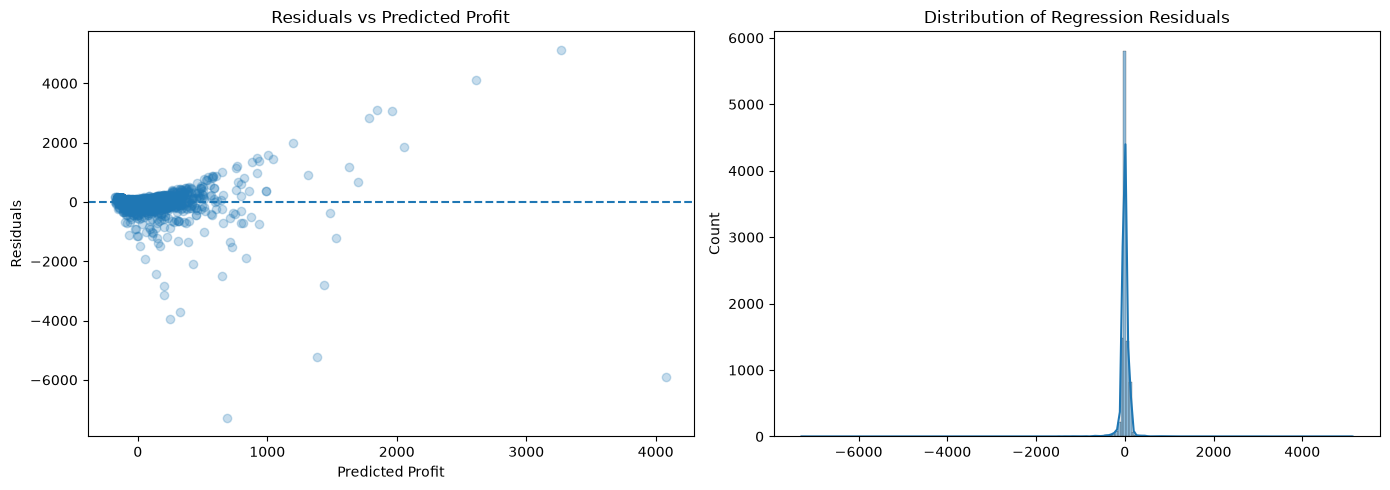

In [9]:
residuals = profit_model.resid
predictions = profit_model.fittedvalues

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(predictions, residuals, alpha=0.25)
axes[0].axhline(0, linestyle="--")
axes[0].set_title("Residuals vs Predicted Profit")
axes[0].set_xlabel("Predicted Profit")
axes[0].set_ylabel("Residuals")

sns.histplot(residuals, kde=True, ax=axes[1])
axes[1].set_title("Distribution of Regression Residuals")

plt.tight_layout()
plt.show()